<h1> Q-Learning

The main difference between Q-learning and SARSA is that, when updating the Q-value, Q-learning assumes that the best action will be chosen in the next state; whereas SARSA uses the value of the action that was actually selected according to the current policy.

Q-learning formula:

$\begin{aligned}
Q(S_t,A_t)\leftarrow Q(S_t,A_t)+\alpha\big[&
R_{t+1}+\gamma\max_a Q(S_{t+1},a)\\
&-Q(S_t,A_t)\big]
\end{aligned}$


Meaning of the parameters:
- $\alpha$: Learning rate; determines how much we learn from new experiences.
- $\gamma$: Discount factor (importance of future rewards).
- $R_{t+1}$: The reward received from the environment.
- $\max_a Q(S_{t+1},a)$: The maximum Q-value among all possible actions in the next state.

The key point lies in this last term: for the purpose of the update, Q-learning considers the maximum Q-value in the next state, even if the agent actually chooses a different action.

For this reason, SARSA is an on-policy algorithm, and Q-Learning is an off-policy algorithm.

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

import gymnasium as gym

<h3> Step 1: Creating the Environment

In [33]:
env = gym.make("CliffWalking-v1")

state, info = env.reset(seed=42)

print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Initial state:", state)

Observation space: Discrete(48)
Action space: Discrete(4)
Initial state: 36


<h3> Step 2: Building the Q-table

In [34]:
Q = np.zeros((
    env.observation_space.n,
    env.action_space.n
))

print("Q-table shape:", Q.shape)
print("Initial Q-values:", Q[36])

Q-table shape: (48, 4)
Initial Q-values: [0. 0. 0. 0.]


<h3> Step 3: ε-greedy implementation

This policy selects a random action with probability $\epsilon$, and otherwise chooses one of the actions with the highest Q-value.

In [35]:
def epsilon_greedy(state, Q, epsilon=0.1):

    if np.random.random() < epsilon:
        return env.action_space.sample()

    best_actions = np.flatnonzero(
        Q[state] == np.max(Q[state])
    )

    return int(np.random.choice(best_actions))

We use random selection among the top actions so that, when the Q-values ​​are equal, action number zero is not always chosen.

<h3> Step 4: Policy Test

In [36]:
state = 36

for _ in range(10):
    action = epsilon_greedy(
        state,
        Q,
        epsilon=0.1
    )

    print(action)

0
3
2
2
3
3
2
1
3
1


<h3> Step 5: Implementation of the Q-Learning Algorithm

In SARSA, we used the Q-value of the actual subsequent action; however, Q-Learning uses the maximum Q-value in the next state:

$\text{Target}=R_{t+1}+\gamma\max_{a'}Q(S_{t+1},a')$

Then:

$Q(S_t,A_t)\leftarrow Q(S_t,A_t)+
\alpha[\text{Target}-Q(S_t,A_t)]$

In [37]:
def train_q_learning(
    env,
    episodes=500,
    alpha=0.5,
    gamma=1.0,
    epsilon=0.1
):
    Q = np.zeros((
        env.observation_space.n,
        env.action_space.n
    ))

    episode_rewards = []
    episode_steps = []

    for _ in range(episodes):
        state, _ = env.reset()

        total_reward = 0
        steps = 0

        while True:
            action = epsilon_greedy(
                state, Q, epsilon
            )

            next_state, reward, terminated, truncated, _ = (
                env.step(action)
            )

            total_reward += reward
            steps += 1

            # Q-Learning Target
            if terminated:
                td_target = reward
            else:
                td_target = (
                    reward
                    + gamma * np.max(Q[next_state])
                )

            Q[state, action] += alpha * (
                td_target - Q[state, action]
            )

            state = next_state

            if terminated or truncated:
                break

        episode_rewards.append(total_reward)
        episode_steps.append(steps)

    return (
        Q,
        np.array(episode_rewards),
        np.array(episode_steps)
    )

If the environment is truncated due to a time limit, this implementation stops the training episode. In this case, the final update still utilizes the Q-value of the next state.

<h3> Step 6: Agent Training

We keep the parameters the same as in the SARSA experiment to ensure a fairer comparison later on.

In [38]:
np.random.seed(42)
env.action_space.seed(42)

Q_qlearning, ql_rewards, ql_steps = train_q_learning(
    env,
    episodes=500,
    alpha=0.5,
    gamma=1.0,
    epsilon=0.1
)

print("Q-table shape:", Q_qlearning.shape)

print(
    "Mean reward (first 50 episodes):",
    np.mean(ql_rewards[:50])
)

print(
    "Mean reward (last 50 episodes):",
    np.mean(ql_rewards[-50:])
)

print(
    "Mean steps (last 50 episodes):",
    np.mean(ql_steps[-50:])
)

Q-table shape: (48, 4)
Mean reward (first 50 episodes): -114.62
Mean reward (last 50 episodes): -54.4
Mean steps (last 50 episodes): 16.78


Initial Q-Learning results indicate that the agent is learning; however, we still need to investigate why its reward was lower compared to SARSA.

#### Analysis of Outputs

- Reward: There has been an improvement of approximately 60.22 units; thus, the agent has demonstrated better overall performance.

- Steps: The average is 16.78 moves, which is lower than the 20.92-move average observed during SARSA training.

- Important Note: Despite the reduction in the number of moves, the reward remains significantly negative. One potential reason for this is the agent falling off a cliff, which incurs a penalty of -100. We must investigate this possibility during the evaluation phase.

These results alone do not indicate whether Q-Learning is superior or inferior to SARSA; the learned policy must still be evaluated under identical conditions.

<h3> Step 7: Plotting the SARSA Learning Curve

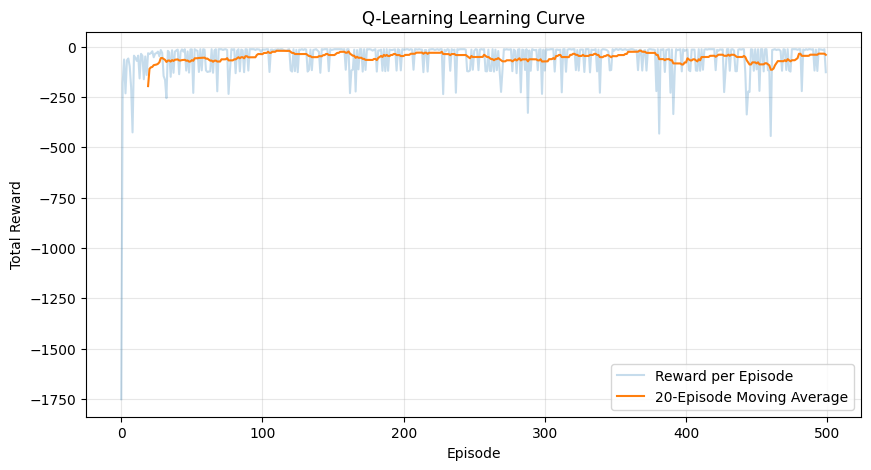

In [39]:
window = 20

ql_moving_avg_rewards = np.convolve(
    ql_rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 5))

plt.plot(
    ql_rewards,
    alpha=0.25,
    label="Reward per Episode"
)

plt.plot(
    np.arange(window - 1, len(ql_rewards)),
    ql_moving_avg_rewards,
    label="20-Episode Moving Average"
)

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Q-Learning Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Q-Learning Learning Curve Analysis

- Start of Training: The reward reaches as low as approximately -1750. This highly negative value is likely due to long episodes and frequent falls off the cliff; each fall incurs a penalty of -100.

- Initial Progress: The moving average rapidly shifts toward less negative values, indicating that the agent is learning better paths.

- Continued Training: The moving average fluctuates primarily within the range of -25 to -100, with occasional sharp drops.

- Conclusion: Performance has improved compared to the start of training; however, the fluctuations suggest that we still need to investigate how often the agent falls and whether it has learned a safe path.

These intermittent drops may be attributed to exploration or the selection of suboptimal paths.

<h3> Step 8: Analyzing the number of moves

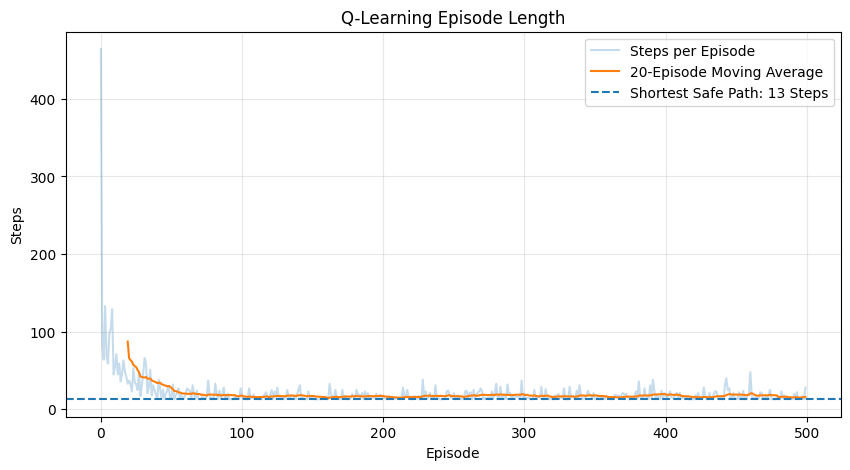

In [40]:
ql_moving_avg_steps = np.convolve(
    ql_steps,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 5))

plt.plot(
    ql_steps,
    alpha=0.25,
    label="Steps per Episode"
)

plt.plot(
    np.arange(window - 1, len(ql_steps)),
    ql_moving_avg_steps,
    label="20-Episode Moving Average"
)

plt.axhline(
    13,
    linestyle="--",
    label="Shortest Safe Path: 13 Steps"
)

plt.xlabel("Episode")
plt.ylabel("Steps")
plt.title("Q-Learning Episode Length")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Q-Learning Episode Length Analysis

- At the beginning of training, some episodes last for hundreds of steps.
- The number of steps decreases rapidly.

- Throughout a large portion of the training, the moving average hovers roughly between 15 and 20 steps.

- The dashed line, representing 13 steps, indicates the shortest safe path.
The average for the last 50 episodes was 16.78 steps; in terms of step count, Q-Learning’s training performance outperformed SARSA, which had an average of 20.92 steps.

However, this alone does not necessarily imply better overall performance; the agent might take a shorter path but fall off the cliff more frequently, thereby incurring penalties.

#### Initial Comparison of SARSA and Q-Learning

| Training Metric | SARSA | Q-Learning |
|---|---|---|
| Reward — First 50 episodes | -111.52 | -114.62 |
| Reward — Last 50 episodes | -22.90 | -54.40 |
| Steps — last 50 episodes | 20.92 | 16.78 |

Current takeaway: SARSA yielded a better reward by the end of training, whereas Q-Learning recorded a lower average number of moves. We cannot yet conclude which algorithm is superior; both must be evaluated using a greedy policy and identical metrics.

<h3> Step 9: Evaluation

In [41]:
def greedy_action(state, Q):
    best_actions = np.flatnonzero(
        Q[state] == np.max(Q[state])
    )

    return int(np.random.choice(best_actions))

In [42]:
def evaluate_q_learning(
    env,
    Q,
    episodes=1000,
    max_steps=1000
):
    rewards = []
    steps_history = []
    cliff_falls = []
    successes = []
    paths = []
    timeouts = 0

    for _ in range(episodes):
        state, _ = env.reset()

        total_reward = 0
        falls = 0
        path = [int(state)]
        reached_goal = False
        timed_out = False

        for step in range(max_steps):
            action = greedy_action(state, Q)

            next_state, reward, terminated, truncated, _ = (
                env.step(action)
            )

            total_reward += reward

            if reward == -100:
                falls += 1

            path.append(int(next_state))
            state = next_state

            if terminated:
                reached_goal = True
                break

            if truncated:
                timed_out = True
                break
        else:
            timed_out = True

        rewards.append(total_reward)
        steps_history.append(step + 1)
        cliff_falls.append(falls)
        successes.append(int(reached_goal))
        paths.append(path)

        if timed_out:
            timeouts += 1

    return {
        "rewards": np.array(rewards),
        "steps": np.array(steps_history),
        "cliff_falls": np.array(cliff_falls),
        "successes": np.array(successes),
        "paths": paths,
        "timeouts": timeouts
    }

In [43]:
np.random.seed(42)

results_ql = evaluate_q_learning(
    env,
    Q_qlearning,
    episodes=1000
)

print(
    "Mean reward:",
    np.mean(results_ql["rewards"])
)

print(
    "Mean steps:",
    np.mean(results_ql["steps"])
)

print(
    "Mean cliff falls per episode:",
    np.mean(results_ql["cliff_falls"])
)

print(
    "Success rate:",
    np.mean(results_ql["successes"])
)

print(
    "Timeout episodes:",
    results_ql["timeouts"]
)

Mean reward: -13.0
Mean steps: 13.0
Mean cliff falls per episode: 0.0
Success rate: 1.0
Timeout episodes: 0


<h3> Step 10: Analyzing the Agent's actual path

In [44]:
path = results_ql["paths"][0]

print("Path length:", len(path) - 1)
print("State path:", path)
print(
    "Grid coordinates:",
    [divmod(state, 12) for state in path]
)

Path length: 13
State path: [36, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 47]
Grid coordinates: [(3, 0), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9), (2, 10), (2, 11), (3, 11)]


After 500 episodes of training, Q-Learning has learned the shortest safe path in the CliffWalking environment. Now, its practical difference from SARSA has become clearly apparent.

#### Experimental Result:

Both algorithms learned a safe policy; however, Q-Learning arrived at the shortest safe path, whereas SARSA selected a path that was four steps longer.
This outcome aligns with the conceptual differences between the two algorithms:
- SARSA utilizes the actual action selected in the next state—meaning it incorporates the effect of its own exploratory policy into the update process.
- Q-Learning uses the maximum Q-value for the next state, directly targeting the value of the optimal subsequent action.

Of course, this experiment alone does not prove that Q-Learning is always superior to SARSA; the result depends on the environment, the parameters, the number of episodes, and the stochastic nature of the training process.

<h3> Step 11: Comparative Plotting of Two Paths

In [45]:
sarsa_path = [
    36, 24, 12, 0,
    1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11,
    23, 35, 47
]

qlearning_path = results_ql["paths"][0]

print("SARSA steps:", len(sarsa_path) - 1)
print("Q-Learning steps:", len(qlearning_path) - 1)

SARSA steps: 17
Q-Learning steps: 13


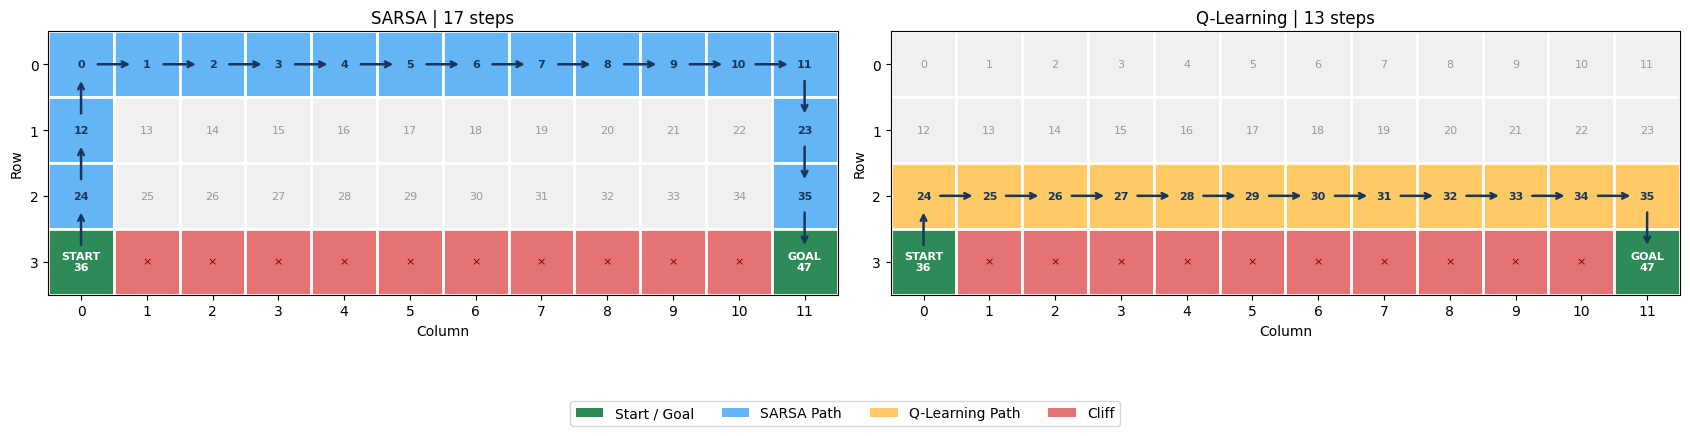

In [46]:
def draw_path(ax, path, title, path_color):

    route_states = set(path)

    for state in range(48):
        row, col = divmod(state, 12)

        if state in (36, 47):
            color = "#2E8B57"

        elif row == 3 and 0 < col < 11:
            color = "#E57373"

        elif state in route_states:
            color = path_color

        else:
            color = "#F0F0F0"

        ax.add_patch(
            Rectangle(
                (col, row), 1, 1,
                facecolor=color,
                edgecolor="white",
                linewidth=2
            )
        )

        if state == 36:
            label = "START\n36"
            text_color = "white"

        elif state == 47:
            label = "GOAL\n47"
            text_color = "white"

        elif row == 3 and 0 < col < 11:
            label = "×"
            text_color = "#7F0000"

        elif state in route_states:
            label = str(state)
            text_color = "#17365D"

        else:
            label = str(state)
            text_color = "#999999"

        ax.text(
            col + 0.5,
            row + 0.5,
            label,
            ha="center",
            va="center",
            fontsize=8,
            color=text_color,
            fontweight="bold" if state in route_states else "normal"
        )

    # فلش جهت حرکت
    for current, nxt in zip(path[:-1], path[1:]):
        r1, c1 = divmod(current, 12)
        r2, c2 = divmod(nxt, 12)

        ax.annotate(
            "",
            xy=(c2 + 0.5, r2 + 0.5),
            xytext=(c1 + 0.5, r1 + 0.5),
            arrowprops=dict(
                arrowstyle="->",
                color="#17365D",
                linewidth=1.8,
                shrinkA=12,
                shrinkB=12
            )
        )

    ax.set_xlim(0, 12)
    ax.set_ylim(4, 0)
    ax.set_aspect("equal")
    ax.set_xticks(np.arange(12) + 0.5)
    ax.set_xticklabels(range(12))
    ax.set_yticks(np.arange(4) + 0.5)
    ax.set_yticklabels(range(4))
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.set_title(f"{title} | {len(path) - 1} steps")


fig, axes = plt.subplots(1, 2, figsize=(17, 5))

draw_path(
    axes[0],
    sarsa_path,
    "SARSA",
    "#64B5F6"
)

draw_path(
    axes[1],
    qlearning_path,
    "Q-Learning",
    "#FFCA65"
)

legend_items = [
    Patch(facecolor="#2E8B57", label="Start / Goal"),
    Patch(facecolor="#64B5F6", label="SARSA Path"),
    Patch(facecolor="#FFCA65", label="Q-Learning Path"),
    Patch(facecolor="#E57373", label="Cliff")
]

fig.legend(
    handles=legend_items,
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.04)
)

plt.tight_layout()
plt.show()

### Summary of the Temporal Difference Learning Section

Our current results show:

- TD(0) Prediction: Learning the state-value function using TD error and bootstrapping.
- SARSA: Learning $Q(s,a)$ using the actual next action; a safe path of 17 steps.
- Q-Learning: Learning $Q(s,a)$ using the maximum Q-value in the next state; a safe path of 13 steps.

A key takeaway from this experiment is that while both algorithms achieved a 100% success rate with zero crashes during evaluation, Q-Learning learned a shorter path.